# Régression logistique : Iris Versicolor vs Virginica

## Objectif

Nous allons construire un modèle simple pour répondre à la question :

**Cette fleur est-elle une Iris Virginica ?**

La variable cible sera :

- `1` : Virginica
- `0` : Versicolor

Nous utiliserons seulement deux variables :

- longueur du pétale ;
- largeur du pétale.

Contrairement à Setosa, Versicolor et Virginica se chevauchent partiellement. Le modèle ne sera donc pas parfait, ce qui permet de mieux comprendre les métriques de classification.

## 1. Importer les bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

RANDOM_STATE = 42

## 2. Charger le jeu de données Iris

In [2]:
iris = load_iris(as_frame=True)

df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Le jeu de données Iris contient trois espèces :

- Setosa ;
- Versicolor ;
- Virginica.

Ici, nous gardons uniquement **Versicolor** et **Virginica** pour créer un problème de classification binaire.

In [3]:
df = df[df["species"].isin(["versicolor", "virginica"])].copy()

df["is_virginica"] = (df["species"] == "virginica").astype(int)

df[["petal length (cm)", "petal width (cm)", "species", "is_virginica"]].head()

,petal length (cm),petal width (cm),species,is_virginica
50,4.7,1.4,versicolor,0
51,4.5,1.5,versicolor,0
52,4.9,1.5,versicolor,0
53,4.0,1.3,versicolor,0
54,4.6,1.5,versicolor,0


## 3. Examiner la variable cible

In [4]:
df["is_virginica"].value_counts()

is_virginica
0    50
1    50
Name: count, dtype: int64

La cible est équilibrée :

- `0` : Versicolor ;
- `1` : Virginica.

## 4. Visualiser les données

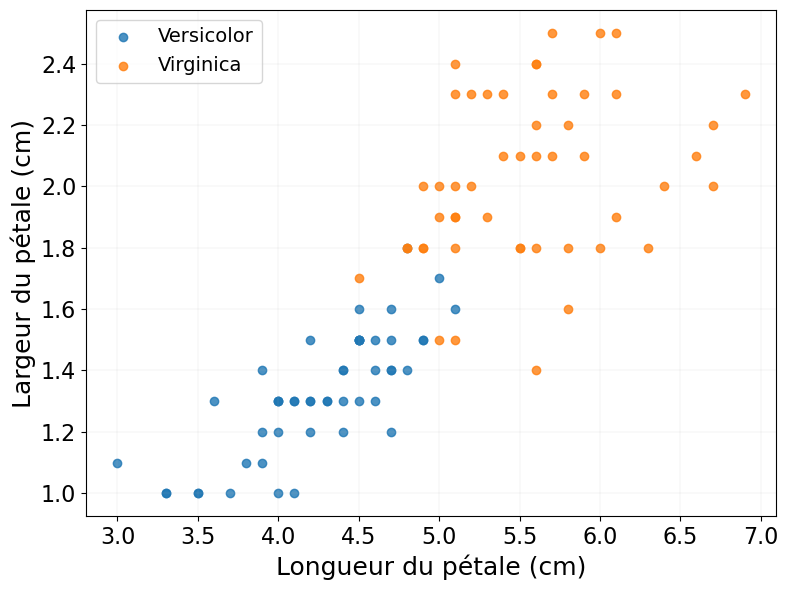

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

for value, label in [(0, "Versicolor"), (1, "Virginica")]:
    subset = df[df["is_virginica"] == value]

    ax.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=label,
        alpha=0.8
    )

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Longueur du pétale (cm)", fontsize=18)
plt.ylabel("Largeur du pétale (cm)", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

Les deux espèces sont assez bien séparées, mais certaines fleurs se chevauchent.

Le problème est donc simple, mais pas parfaitement séparable.

## 5. Définir les entrées et la cible

In [6]:
features = [
    "petal length (cm)",
    "petal width (cm)"
]

X = df[features]
y = df["is_virginica"]

print("X :", X.shape)
print("y :", y.shape)

X : (100, 2)
y : (100,)


## 6. Séparer les données d'entraînement et de test

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (75, 2)
Test : (25, 2)


Le modèle est entraîné sur 75 % des données puis évalué sur les 25 % restantes.

## 7. Entraîner une régression logistique

La régression logistique calcule d'abord une combinaison linéaire :


$z = b + w_1x_1 + w_2x_2$


Puis elle applique la fonction sigmoïde :


$p = \frac{1}{1 + e^{-z}}$


La sortie `p` est comprise entre 0 et 1.

In [8]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Modèle entraîné.")

Modèle entraîné.


## 8. Prédire des probabilités

In [9]:
y_prob = model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results["Observation"] = y_test.values
results["Probabilite_Virginica"] = y_prob

results.head(10)

,petal length (cm),petal width (cm),Observation,Probabilite_Virginica
135,6.1,2.3,1,0.987229
113,5.0,2.0,1,0.711601
106,4.5,1.7,1,0.263482
85,4.5,1.6,0,0.222482
103,5.6,1.8,1,0.877606
134,5.6,1.4,1,0.745869
91,4.6,1.4,0,0.190671
116,5.5,1.8,1,0.847835
119,5.0,1.5,1,0.446852
101,5.1,1.9,1,0.717500


La colonne `Probabilite_Virginica` correspond à la probabilité estimée que la fleur appartienne à l'espèce Virginica.

## 9. Transformer les probabilités en classes

Avec un seuil de `0.5` :

$
\hat{y} =
\begin{cases}
1 & \text{si } p \geq 0.5 \\
0 & \text{si } p < 0.5
\end{cases}
$

Ici :

- `1` signifie Virginica ;
- `0` signifie Versicolor.

In [10]:
threshold = 0.5

y_pred = (y_prob >= threshold).astype(int)

results["Prediction"] = y_pred

results.head(10)

,petal length (cm),petal width (cm),Observation,Probabilite_Virginica,Prediction
135,6.1,2.3,1,0.987229,1
113,5.0,2.0,1,0.711601,1
106,4.5,1.7,1,0.263482,0
85,4.5,1.6,0,0.222482,0
103,5.6,1.8,1,0.877606,1
134,5.6,1.4,1,0.745869,1
91,4.6,1.4,0,0.190671,0
116,5.5,1.8,1,0.847835,1
119,5.0,1.5,1,0.446852,0
101,5.1,1.9,1,0.717500,1


## 10. Visualiser la frontière de décision

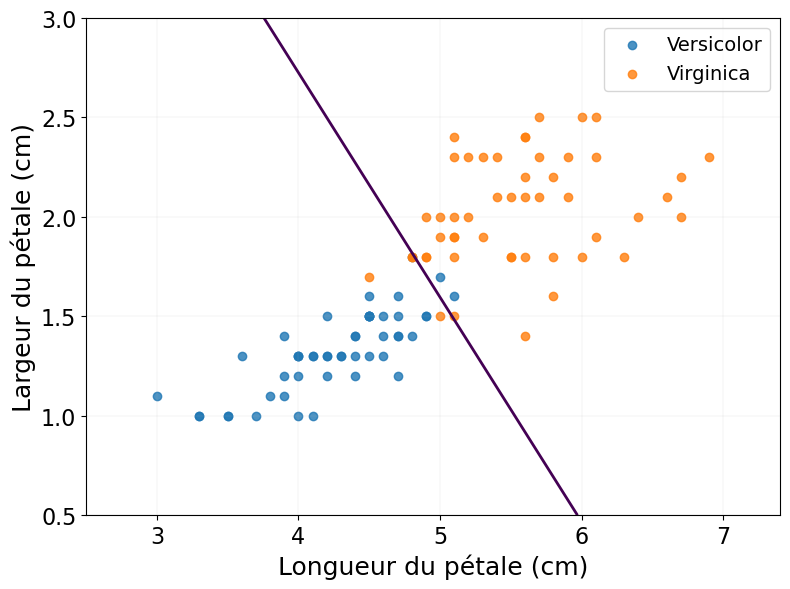

In [11]:
x_min = X["petal length (cm)"].min() - 0.5
x_max = X["petal length (cm)"].max() + 0.5

y_min = X["petal width (cm)"].min() - 0.5
y_max = X["petal width (cm)"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "petal length (cm)": xx.ravel(),
    "petal width (cm)": yy.ravel()
})

grid_prob = model.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))

ax.contour(
    xx,
    yy,
    grid_prob,
    levels=[0.5],
    linewidths=2
)

for value, label in [(0, "Versicolor"), (1, "Virginica")]:
    subset = df[df["is_virginica"] == value]

    ax.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=label,
        alpha=0.8
    )

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Longueur du pétale (cm)", fontsize=18)
plt.ylabel("Largeur du pétale (cm)", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

La ligne représente la frontière où la probabilité prédite vaut environ `0.5`.

Les fleurs proches de cette frontière sont les cas les plus difficiles à classer.

## 11. Matrice de confusion

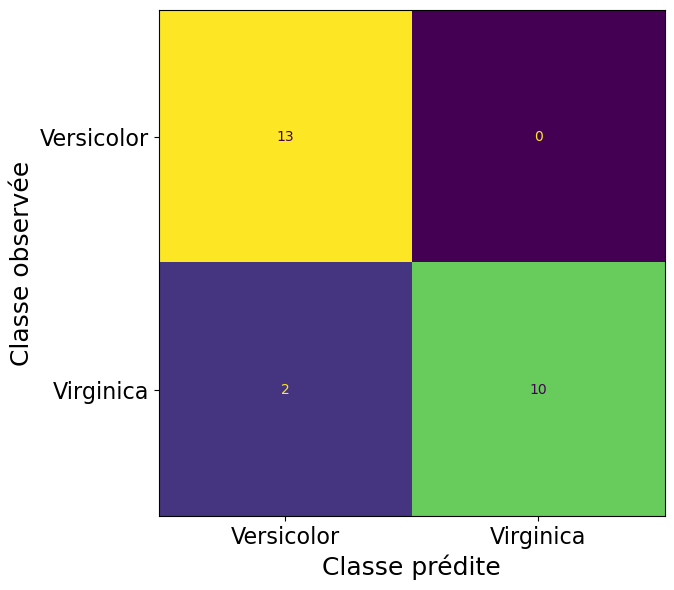

In [12]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Versicolor", "Virginica"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Classe prédite", fontsize=18)
plt.ylabel("Classe observée", fontsize=18)
plt.grid(False)

plt.tight_layout()
plt.show()

La matrice de confusion permet de voir :

- les Versicolor correctement classées ;
- les Virginica correctement classées ;
- les faux positifs ;
- les faux négatifs.

## 12. Calculer les métriques

In [13]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({
    "Métrique": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Valeur": [
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Métrique,Valeur
0,Accuracy,0.920000
1,Precision,1.000000
2,Recall,0.833333
3,F1-score,0.909091
4,ROC-AUC,0.980769


### Accuracy


$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$


### Precision

$
Precision = \frac{TP}{TP + FP}
$

Parmi les fleurs prédites Virginica, combien sont réellement Virginica ?

### Recall

$
Recall = \frac{TP}{TP + FN}
$

Parmi toutes les vraies Virginica, combien sont correctement détectées ?

### F1-score

$
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$

### ROC-AUC

Le ROC-AUC évalue la capacité du modèle à distinguer les deux espèces pour tous les seuils possibles.

## 13. Identifier les erreurs du modèle

In [14]:
errors = results[results["Observation"] != results["Prediction"]]

errors

,petal length (cm),petal width (cm),Observation,Probabilite_Virginica,Prediction
106,4.5,1.7,1,0.263482,0
119,5.0,1.5,1,0.446852,0


Ces observations sont particulièrement intéressantes car elles permettent de comprendre où les deux classes se chevauchent.

## 14. Changer le seuil de classification

In [15]:
thresholds = [0.2, 0.4, 0.5, 0.6, 0.8]

rows = []

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    rows.append({
        "Seuil": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(rows)

threshold_results

,Seuil,Accuracy,Precision,Recall,F1-score
0,0.2,0.88,0.800000,1.000000,0.888889
1,0.4,0.92,0.916667,0.916667,0.916667
2,0.5,0.92,1.000000,0.833333,0.909091
3,0.6,0.88,1.000000,0.750000,0.857143
4,0.8,0.72,1.000000,0.416667,0.588235


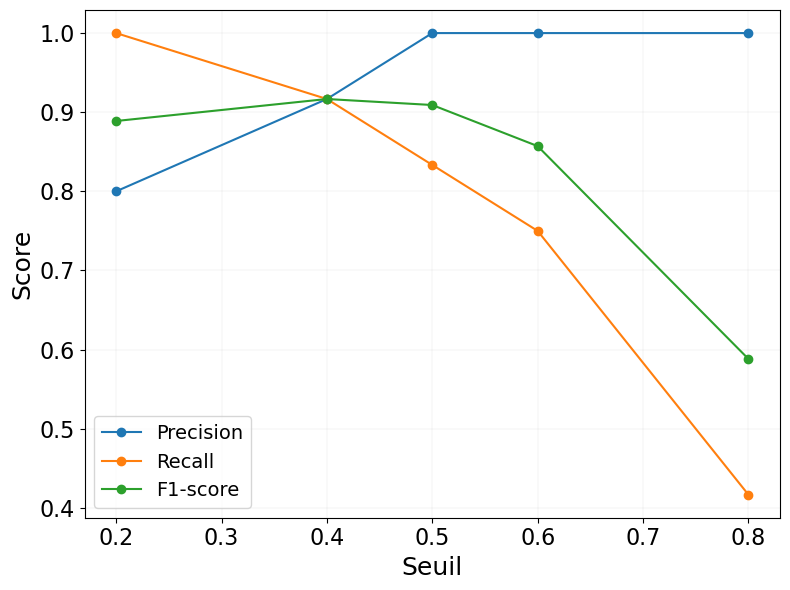

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    threshold_results["Seuil"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    threshold_results["Seuil"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    threshold_results["Seuil"],
    threshold_results["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Seuil", fontsize=18)
plt.ylabel("Score", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

Lorsque le seuil augmente, le modèle devient plus exigeant avant de prédire Virginica.

Cela peut :

- augmenter la precision ;
- diminuer le recall ;
- modifier le nombre de faux positifs et de faux négatifs.

## 15. Courbe ROC

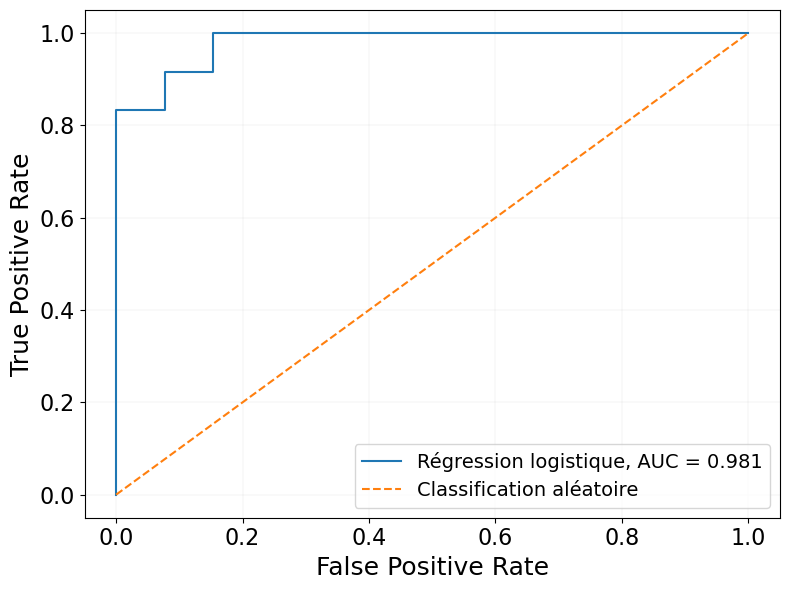

In [17]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr,
    tpr,
    label=f"Régression logistique, AUC = {auc:.3f}"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classification aléatoire"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("False Positive Rate", fontsize=18)
plt.ylabel("True Positive Rate", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

La courbe ROC montre le compromis entre :

- True Positive Rate ;
- False Positive Rate.

Une AUC proche de `1` signifie que le modèle sépare bien les deux espèces, même s'il peut encore faire quelques erreurs au seuil de `0.5`.

## 16. Regarder les coefficients

In [18]:
coef_df = pd.DataFrame({
    "Variable": features,
    "Coefficient": model.coef_[0]
})

coef_df

,Variable,Coefficient
0,petal length (cm),2.522353
1,petal width (cm),2.233145


Un coefficient positif signifie qu'une augmentation de la variable tend à augmenter la probabilité prédite de Virginica.

Un coefficient négatif signifie l'inverse.

## 17. Faire une prédiction manuelle

In [19]:
new_flower = pd.DataFrame({
    "petal length (cm)": [5.0],
    "petal width (cm)": [1.7]
})

probability = model.predict_proba(new_flower)[0, 1]
prediction = model.predict(new_flower)[0]

print(f"Probabilité Virginica : {probability:.3f}")
print(f"Classe prédite        : {prediction}")

Probabilité Virginica : 0.558
Classe prédite        : 1


Essayez de modifier la longueur et la largeur du pétale pour observer comment la probabilité change.

## 18. Résumé

Dans ce notebook :

1. nous avons construit un problème binaire Versicolor vs Virginica ;
2. nous avons entraîné une régression logistique ;
3. le modèle produit une probabilité ;
4. un seuil transforme cette probabilité en classe ;
5. nous avons visualisé la frontière de décision ;
6. nous avons étudié la matrice de confusion ;
7. nous avons calculé accuracy, precision, recall, F1-score et ROC-AUC ;
8. nous avons identifié les erreurs du modèle ;
9. nous avons étudié l'effet du seuil de classification.

## 19. Exercices

### Exercice 1

Changez le seuil de `0.5` à `0.3`.

Comparez :

- accuracy ;
- precision ;
- recall ;
- matrice de confusion.

### Exercice 2

Changez le seuil à `0.7`.

Que devient le recall ?

### Exercice 3

Utilisez seulement :

- `sepal length (cm)` ;
- `sepal width (cm)`.

Réentraînez le modèle et comparez les performances.

### Exercice 4

Utilisez les quatre variables disponibles.

Comparez le nouveau modèle avec celui utilisant seulement les dimensions des pétales.

### Exercice 5

Examinez les fleurs mal classées.

Sont-elles proches de la frontière de décision ?

### Exercice 6

Créez plusieurs nouvelles fleurs avec des dimensions proches de la frontière et observez comment la probabilité change.